In [147]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict , Dict , List , Annotated
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI
from pydantic import BaseModel , Field
import os
import operator

In [148]:
load_dotenv()  # Load environment variables from .env file

True

In [149]:
llm = ChatGoogleGenerativeAI(
    model = os.getenv('GOOGLE_MODEL'),
    google_api_key = os.getenv('GOOGLE_API_KEY'),
    temperature = 0.7,
)

In [150]:
class EvalutionSchema(BaseModel):
    feedback: str = Field(..., description="Detailed feedback on the essay")
    score: int = Field(..., description="Score assigned to the essay based on evaluation criteria" , ge=0 , le=10)

In [151]:
structure_llm = llm.with_structured_output(EvalutionSchema)

In [152]:
class EssayState(TypedDict):
    essay: str
    language_feedback: str
    analysis_feedback: str
    clarity_feedback: str
    overall_feedback: str
    individual_scores: Annotated[List[int] , operator.add]
    avg_score: float

In [153]:
def language_feedback(state: EssayState) -> Dict:
    prompt = f"Please provide feedback on the language used in the following essay and score out of 0 to 10:\n\n{state['essay']}"
    output = structure_llm.invoke(prompt)
    return {'language_feedback': output.feedback, 'individual_scores': [output.score]}

In [154]:
def analysis_feedback(state: EssayState) -> Dict:
    prompt = f"Please provide feedback on the analysis in the following essay and score out of 0 to 10 :\n\n{state['essay']}"
    output = structure_llm.invoke(prompt)
    return {'analysis_feedback': output.feedback, 'individual_scores': [output.score]}

In [155]:
def clarity_feedback(state: EssayState) -> Dict:
    prompt = f"Please provide feedback on the clarity of the following essay and score out of 0 to 10:\n\n{state['essay']}"
    output = structure_llm.invoke(prompt)
    return {'clarity_feedback': output.feedback, 'individual_scores': [output.score]}

In [156]:
def overall_feedback(state: EssayState) -> Dict:
    prompt = f"Please provide overall feedback on the following language, analysis, and clarity feedback and score out of 0 to 10:\n\nLanguage Feedback: {state['language_feedback']}\nAnalysis Feedback: {state['analysis_feedback']}\nClarity Feedback: {state['clarity_feedback']}"
    output = llm.invoke(prompt)
    avg_score = sum(state['individual_scores']) / len(state['individual_scores']) if state['individual_scores'] else 0
    return {'overall_feedback': output, 'avg_score': avg_score}


In [157]:
graph = StateGraph(EssayState)
# Add nodes to the graph
graph.add_node('language_feedback', language_feedback)
graph.add_node('analysis_feedback', analysis_feedback)
graph.add_node('clarity_feedback', clarity_feedback)
graph.add_node('overall_feedback', overall_feedback)

# Add edges to define the flow of evaluation
graph.add_edge(START, 'language_feedback')
graph.add_edge(START , 'analysis_feedback')
graph.add_edge(START , 'clarity_feedback')
graph.add_edge('language_feedback', 'overall_feedback')
graph.add_edge('analysis_feedback', 'overall_feedback')
graph.add_edge('clarity_feedback', 'overall_feedback')
graph.add_edge('overall_feedback', END)

workflow = graph.compile()

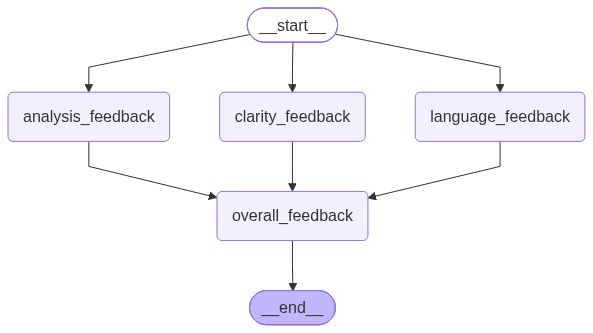

In [158]:
workflow

In [159]:
essay = """Artificial Intelligence (AI) is one of the most important technologies in the modern world. It is a technology that allows computers and machines to think, learn, and solve problems like humans. AI is changing our daily lives and making many tasks easier and faster.

Bangladesh is a developing country, and AI can play an important role in its development. Today, many students, teachers, developers, and businesses are using AI technology. Tools like ChatGPT and Google Gemini are becoming popular in Bangladesh.

AI can be used in many sectors of Bangladesh. In education, students can use AI to learn new things, understand difficult topics, and improve their knowledge. Teachers can use AI to prepare lessons and educational materials.

In healthcare, AI can help doctors identify diseases and analyze medical reports. It can also support people living in rural areas by providing basic health information.

In agriculture, AI can help farmers identify crop diseases, understand weather conditions, and improve agricultural production. This can help farmers save time and reduce losses.

AI can also improve business and industry. Companies can use AI for customer support, data analysis, and automatic services. In the garment industry, AI can help improve product quality and production efficiency.

However, Bangladesh faces some challenges in developing AI. These include a lack of skilled professionals, limited technology infrastructure, high development costs, and insufficient research facilities. There are also concerns about data privacy and job losses due to automation.

To overcome these challenges, Bangladesh needs to invest in AI education, research, and technology. Schools and universities should provide students with opportunities to learn programming, machine learning, and artificial intelligence.

The future of AI in Bangladesh is promising. Young people can play an important role in developing new AI applications and technologies. By learning AI and using it responsibly, Bangladesh can become a stronger and more advanced country.

In conclusion, Artificial Intelligence is a great opportunity for Bangladesh. It can improve education, healthcare, agriculture, business, and many other sectors. With proper knowledge, investment, and hard work, AI can help build a smarter and more developed Bangladesh."""


In [160]:
essay2 = """Artificial Intelligence is a good technology in the modern world. It is very useful for people. AI means Artificial Intelligence. It helps computers to work like humans. Nowadays, many people in Bangladesh use AI in their daily life.

AI is used in education, business, hospitals, agriculture, and many other sectors. Students use AI to write essays, learn English, and solve mathematics problems. Teachers can use AI to make lessons. Doctors can use AI to find diseases. Farmers can use AI to know about crop diseases and weather conditions.

In Bangladesh, AI is becoming popular day by day. Many young people are learning AI and computer programming. They want to build their careers in the technology sector. AI can help Bangladesh become a developed country.

But AI also has some bad sides. Many people may lose their jobs because of AI. Some students use AI too much and do not study properly. AI can also give wrong information. So, we should use AI carefully.

The government should provide more opportunities for students to learn about AI. Schools and colleges should teach modern technology. Young people should learn computer skills and use AI for good purposes.

In conclusion, AI is very important for Bangladesh. It has both advantages and disadvantages. If we use AI properly, it can help our country develop and improve people's lives."""

In [161]:
initial_state = {
    'essay': essay2,
}

In [162]:
final_state = workflow.invoke(initial_state)
final_state

{'essay': "Artificial Intelligence is a good technology in the modern world. It is very useful for people. AI means Artificial Intelligence. It helps computers to work like humans. Nowadays, many people in Bangladesh use AI in their daily life.\n\nAI is used in education, business, hospitals, agriculture, and many other sectors. Students use AI to write essays, learn English, and solve mathematics problems. Teachers can use AI to make lessons. Doctors can use AI to find diseases. Farmers can use AI to know about crop diseases and weather conditions.\n\nIn Bangladesh, AI is becoming popular day by day. Many young people are learning AI and computer programming. They want to build their careers in the technology sector. AI can help Bangladesh become a developed country.\n\nBut AI also has some bad sides. Many people may lose their jobs because of AI. Some students use AI too much and do not study properly. AI can also give wrong information. So, we should use AI carefully.\n\nThe governm